# Lab 5 — Motor parameter identification (student 240191)

**Setup.** Robot trik-6fc169, **lifted so both wheels spin freely**. Left wheel = motor **M4** / encoder E4,
right wheel = motor **M3** / encoder E3. Programs built from TRIK Studio blocks (no JS/Python):
`motor_steps.qrs` (step series, Program A) and `motor_signal.qrs` (complex signal, Program B); the per-motor
copies used on the robot are in `programs/`. Timer delay 5 ms in every logging loop.

| File in `motor_data/` | Program | Motor |
|---|---|---|
| `steps_M4_91.txt`, `steps_M4_run2_91.txt` | step series −100…100 % (10 % apart), 2 s on + 1 s coasting, run twice | M4 |
| `steps_M3_91.txt`, `steps_M3_run2_91.txt` | same | M3 |
| `signal_chirp_M4_91.txt`, `signal_chirp_M3_91.txt` | chirp A = 60 %, 0.2 → 4 Hz over 10 s, then 1 s coasting | M4, M3 |
| `signal_square_M4_91.txt`, `signal_square_M3_91.txt` | square A = 60 %, P = 1 s, 8 s, then 1 s coasting | M4, M3 |
| `battery.txt` | battery voltage before / after every run | |

Every line of a data file is `angle (deg), time (ms), PWM (%)`.

## 1. Motor model

$$\frac{d\omega}{dt} = \frac{U}{T_m k_e} - \frac{\omega}{T_m}, \qquad \frac{d\theta}{dt} = \omega,
\qquad \theta(t) = \omega_{ss}\left(t - T_m + T_m e^{-t/T_m}\right),\quad \omega_{ss} = U/k_e$$

✍️ *Your own words:* what $U$, $\theta$, $\omega$, $\omega_{ss}$, $T_m$, $k_e$ mean and their units;
how $\theta(t)$ follows from the differential equation for a step from rest; the model assumptions
(no inductance, linear viscous friction, constant load, constant battery voltage within a run).

In [1]:
import os
import numpy as np                      # array work
import matplotlib.pyplot as plt         # plots
from scipy import optimize              # curve_fit
from scipy.integrate import odeint      # ODE solver

DATA = 'motor_data'
if not os.path.isdir(DATA):             # Colab: upload motor_data.zip (the motor_data folder zipped)
    import zipfile
    from google.colab import files
    files.upload()
    zipfile.ZipFile('motor_data.zip').extractall('.')

MOTORS = {'M4': 'left', 'M3': 'right'}
STEPS = {m: [f'steps_{m}_91.txt', f'steps_{m}_run2_91.txt'] for m in MOTORS}
SIGNALS = {m: {'chirp': f'signal_chirp_{m}_91.txt', 'square': f'signal_square_{m}_91.txt'} for m in MOTORS}


def load(name):
    """Angle [rad] and time [s] from the first sample, PWM [%]; t0_ms = time() of the first sample."""
    a, t, u = np.loadtxt(os.path.join(DATA, name), delimiter=',', unpack=True)
    return np.deg2rad(a), (t - t[0]) / 1000, u, t[0]


# battery voltage: mean of the readings before and after each run
U_bat = {}
for line in open(os.path.join(DATA, 'battery.txt')):
    if line.startswith('#') or line.startswith('file'):
        continue
    f, before, after, _ = line.strip().split(',')
    U_bat[f] = (float(before) + float(after)) / 2
for f, U in U_bat.items():
    print(f'{f:26s} U_bat = {U:.3f} V')

steps_M4_91.txt            U_bat = 11.843 V
steps_M4_run2_91.txt       U_bat = 11.895 V
steps_M3_91.txt            U_bat = 11.889 V
steps_M3_run2_91.txt       U_bat = 11.849 V
signal_chirp_M4_91.txt     U_bat = 11.875 V
signal_chirp_M3_91.txt     U_bat = 11.869 V
signal_square_M4_91.txt    U_bat = 11.863 V
signal_square_M3_91.txt    U_bat = 11.869 V


## 2. Sampling interval

The Timer block waits 5 ms, but every loop pass also reads the encoder and writes a line to the file.

steps_M4_91.txt            mean  19.4 ms, median   20, min  13, max   44
steps_M4_run2_91.txt       mean  19.7 ms, median   20, min  13, max   45
steps_M3_91.txt            mean  20.2 ms, median   20, min  13, max   61
steps_M3_run2_91.txt       mean  19.9 ms, median   20, min  12, max   65
signal_chirp_M4_91.txt     mean  26.5 ms, median   27, min  14, max   51
signal_square_M4_91.txt    mean  26.3 ms, median   27, min  13, max   49
signal_chirp_M3_91.txt     mean  26.6 ms, median   27, min  14, max   58
signal_square_M3_91.txt    mean  26.3 ms, median   26, min  14, max   44


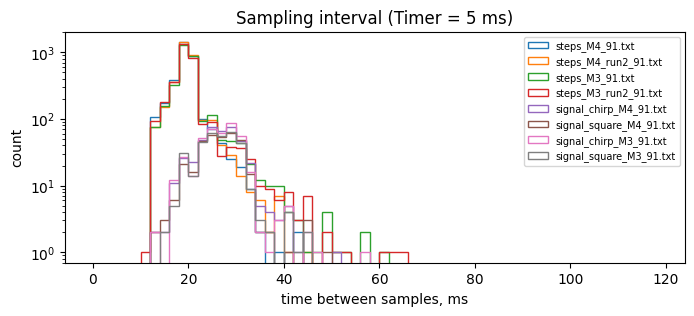

In [2]:
fig, ax = plt.subplots(figsize=(8, 3))
for name in STEPS['M4'] + STEPS['M3'] + [f for m in MOTORS for f in SIGNALS[m].values()]:
    _, t, _, _ = load(name)
    dt = np.diff(t) * 1000
    print(f'{name:26s} mean {dt.mean():5.1f} ms, median {np.median(dt):4.0f}, min {dt.min():3.0f}, max {dt.max():4.0f}')
    ax.hist(dt, bins=np.arange(0, 120, 2), histtype='step', label=name)
ax.set(yscale='log', xlabel='time between samples, ms', ylabel='count', title='Sampling interval (Timer = 5 ms)')
ax.legend(fontsize=7); plt.show()

## 3. Step responses

The step file is split into segments wherever the PWM column changes. Each non-zero segment (2 s with the
motor on) is shifted to start at zero angle and zero time and fitted with the model from the course
notebook. Bounds keep $T_m$ positive (without them the fit diverges at ±100 %).

In [3]:
def model(t, speed, T_m):
    return speed * t - speed * T_m + speed * T_m * np.exp(-t / T_m)


def segments(u):
    """(start, end) index pairs of runs with constant PWM."""
    cut = np.flatnonzero(np.diff(u)) + 1
    return list(zip(np.r_[0, cut], np.r_[cut, len(u)]))


def fit_steps(name):
    th, t, u, _ = load(name)
    rows = []
    for s, e in segments(u):
        if u[s] == 0:
            continue
        t_seg, th_seg = t[s:e] - t[s], th[s:e] - th[s]
        popt, pcov = optimize.curve_fit(model, t_seg, th_seg, p0=[0.15 * u[s], 0.1],
                                        bounds=([-30, 0.005], [30, 2]))
        rows.append([u[s], *popt, *np.sqrt(np.diag(pcov))])
    return np.array(rows)          # columns: PWM, speed, T_m, speed_err, T_m_err


fits = {name: fit_steps(name) for m in MOTORS for name in STEPS[m]}
for m in MOTORS:
    r1, r2 = (fits[n] for n in STEPS[m])
    print(f'Motor {m} ({MOTORS[m]})      run 1                         run 2')
    print(' PWM   omega_ss, rad/s   T_m, ms           omega_ss, rad/s   T_m, ms')
    for a, b in zip(r1, r2):
        print(f'{a[0]:4.0f}  {a[1]:6.2f} ± {a[3]:.2f}   {a[2] * 1000:4.0f} ± {a[4] * 1000:3.0f}      '
              f'{b[1]:6.2f} ± {b[3]:.2f}   {b[2] * 1000:4.0f} ± {b[4] * 1000:3.0f}')

Motor M4 (left)      run 1                         run 2
 PWM   omega_ss, rad/s   T_m, ms           omega_ss, rad/s   T_m, ms
-100  -14.56 ± 0.00     42 ±   0      -14.62 ± 0.00     38 ±   0
 -90  -13.20 ± 0.00     61 ±   0      -13.26 ± 0.00     68 ±   0
 -80  -12.11 ± 0.00     98 ±   0      -12.11 ± 0.00     87 ±   0
 -70  -10.88 ± 0.01    120 ±   1      -10.91 ± 0.00    125 ±   0
 -60   -9.81 ± 0.00    157 ±   0       -9.80 ± 0.01    143 ±   1
 -50   -8.90 ± 0.00    161 ±   1       -8.90 ± 0.00    167 ±   1
 -40   -8.18 ± 0.00    202 ±   1       -8.16 ± 0.00    187 ±   1
 -30   -6.66 ± 0.01    228 ±   1       -6.77 ± 0.00    221 ±   1
 -20   -5.46 ± 0.00    268 ±   1       -5.48 ± 0.01    249 ±   1
 -10   -3.79 ± 0.01    241 ±   2       -3.97 ± 0.00    285 ±   1
  10    4.03 ± 0.00    320 ±   1        4.08 ± 0.01    334 ±   2
  20    5.69 ± 0.00    270 ±   1        5.68 ± 0.00    243 ±   1
  30    7.03 ± 0.00    256 ±   1        7.06 ± 0.00    235 ±   1
  40    8.62 ± 0.01    183 ± 

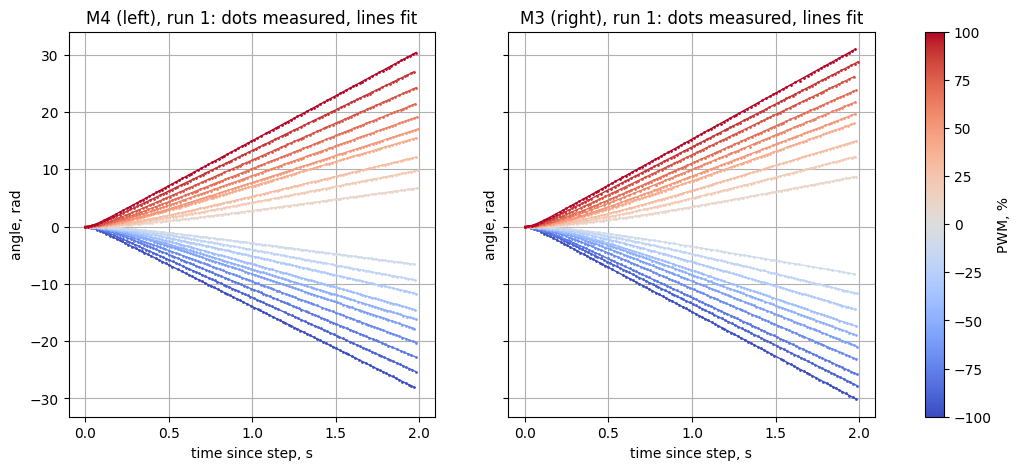

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, m in zip(axs, MOTORS):
    th, t, u, _ = load(STEPS[m][0])
    cmap = plt.cm.coolwarm
    for (s, e), row in zip([se for se in segments(u) if u[se[0]] != 0], fits[STEPS[m][0]]):
        t_seg, th_seg = t[s:e] - t[s], th[s:e] - th[s]
        c = cmap((u[s] + 100) / 200)
        ax.plot(t_seg, th_seg, '.', ms=2, color=c)
        ax.plot(t_seg, model(t_seg, *row[1:3]), '-', lw=1, color=c)
    ax.set(title=f'{m} ({MOTORS[m]}), run 1: dots measured, lines fit',
           xlabel='time since step, s', ylabel='angle, rad'); ax.grid(True)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(-100, 100))
fig.colorbar(sm, ax=axs, label='PWM, %'); plt.show()

*Caption:* step responses θ(t) for every PWM level (2 s with the motor on), measured samples and the fitted
first-order model.

## 4. Speed and time constant versus PWM

The linear part is fitted separately for each direction over |PWM| = 20…100 % (both runs together).
`PWM at ω = 0` is where the fitted line crosses zero speed. The real dead zone is checked on the chirp
(section 5): the PWM at which the wheel first moves after the input crosses zero.

M4 forward : omega = 0.1208·PWM +3.39 rad/s, PWM at omega = 0:  -28.0 %, residual at +100 %: +0.28 rad/s
M4 backward: omega = 0.1099·PWM -3.40 rad/s, PWM at omega = 0:  +30.9 %, residual at -100 %: -0.21 rad/s
M3 forward : omega = 0.1022·PWM +5.86 rad/s, PWM at omega = 0:  -57.4 %, residual at +100 %: -0.02 rad/s
M3 backward: omega = 0.1009·PWM -5.48 rad/s, PWM at omega = 0:  +54.3 %, residual at -100 %: +0.07 rad/s


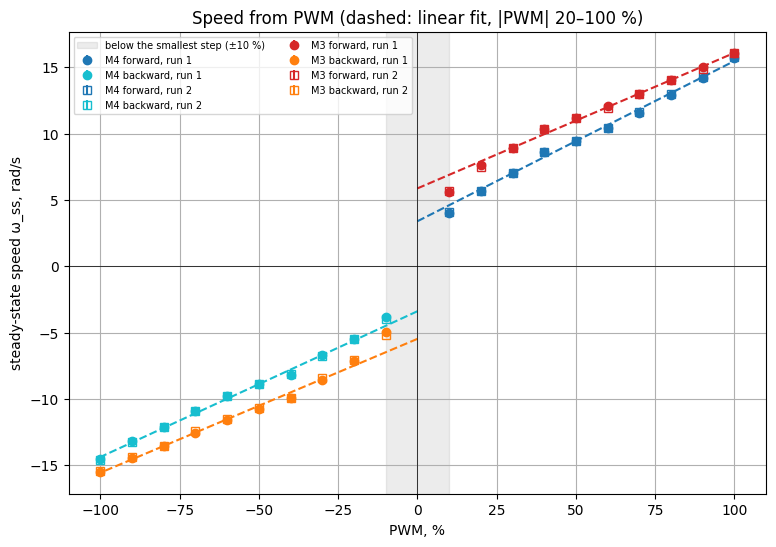

In [5]:
LIN = (20, 100)                 # |PWM| range of the linear fit, %
DIRS = {'forward': 1, 'backward': -1}
lines = {}
for m in MOTORS:
    both = np.vstack([fits[n] for n in STEPS[m]])
    for d, sgn in DIRS.items():
        sel = (sgn * both[:, 0] >= LIN[0]) & (sgn * both[:, 0] <= LIN[1])
        k, b = np.polyfit(both[sel, 0], both[sel, 1], 1)
        lines[m, d] = k, b
        resid_100 = both[both[:, 0] == 100 * sgn, 1].mean() - (k * 100 * sgn + b)
        print(f'{m} {d:8s}: omega = {k:.4f}·PWM {b:+.2f} rad/s, PWM at omega = 0: {-b / k:+6.1f} %, '
              f'residual at {100 * sgn:+d} %: {resid_100:+.2f} rad/s')

fig, ax = plt.subplots(figsize=(9, 6))
colors = {('M4', 'forward'): 'tab:blue', ('M4', 'backward'): 'tab:cyan',
          ('M3', 'forward'): 'tab:red', ('M3', 'backward'): 'tab:orange'}
for m in MOTORS:
    for i, n in enumerate(STEPS[m]):
        r = fits[n]
        for d, sgn in DIRS.items():
            sel = sgn * r[:, 0] > 0
            ax.errorbar(r[sel, 0], r[sel, 1], yerr=r[sel, 3], fmt='o' if i == 0 else 's', mfc='none' if i else None,
                        color=colors[m, d], label=f'{m} {d}, run {i + 1}')
    for d, sgn in DIRS.items():
        k, b = lines[m, d]
        p = np.linspace(0, 100, 50) * sgn
        ax.plot(p, k * p + b, '--', color=colors[m, d])
ax.axvspan(-10, 10, color='grey', alpha=.15, label='below the smallest step (±10 %)')
ax.axhline(0, color='k', lw=.5); ax.axvline(0, color='k', lw=.5)
ax.set(xlabel='PWM, %', ylabel='steady-state speed ω_ss, rad/s', title='Speed from PWM (dashed: linear fit, |PWM| 20–100 %)')
ax.grid(True); ax.legend(fontsize=7, ncol=2); plt.show()

*Caption:* ω_ss against PWM for both motors and both directions, two runs each, with the linear fit of
each direction. Error bars are the standard errors of the step fits.

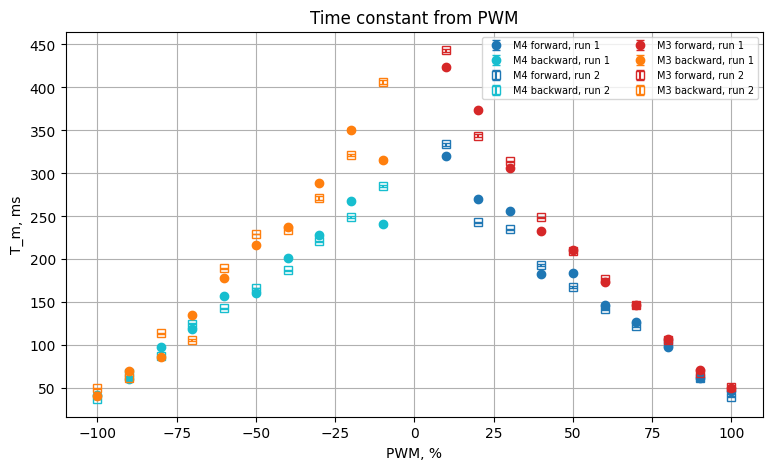

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for m in MOTORS:
    for i, n in enumerate(STEPS[m]):
        r = fits[n]
        for d, sgn in DIRS.items():
            sel = sgn * r[:, 0] > 0
            ax.errorbar(r[sel, 0], r[sel, 2] * 1000, yerr=r[sel, 4] * 1000, fmt='o' if i == 0 else 's',
                        mfc='none' if i else None, color=colors[m, d], capsize=3, label=f'{m} {d}, run {i + 1}')
ax.set(xlabel='PWM, %', ylabel='T_m, ms', title='Time constant from PWM'); ax.grid(True)
ax.legend(fontsize=7, ncol=2); plt.show()

*Caption:* fitted T_m against PWM with standard-error bars, both motors, both directions, both runs.

## 5. Actuation lag and dead zone

**Lag:** time from the step command to the first sample where the wheel has turned 1°.

**Dead zone:** every ±10 % step turns the wheel, so the dead zone is below 10 % in both directions. The
chirp starts from rest and its PWM rises slowly (≈ 75 %/s), so the PWM at which the wheel first turns 2°,
taken one lag earlier, is the forward breakaway threshold. Later zero crossings of the chirp cannot be
used: the wheel is still spinning the other way when the input reverses.

In [7]:
lag = {}
for m in MOTORS:
    lags = []
    for n in STEPS[m]:
        th, t, u, _ = load(n)
        for s, e in segments(u):
            if u[s] != 0:
                j = np.argmax(np.sign(u[s]) * (th[s:e] - th[s]) >= np.deg2rad(1))
                lags.append(t[s + j] - t[s])
    lag[m] = np.mean(lags)
    print(f'{m}: lag to the first 1° {np.mean(lags) * 1000:.0f} ms on average '
          f'(min {min(lags) * 1000:.0f}, max {max(lags) * 1000:.0f})')

breakaway = {}
for m in MOTORS:
    th, t, u, _ = load(SIGNALS[m]['chirp'])
    j = np.argmax(th - th[0] >= np.deg2rad(2))
    breakaway[m] = np.interp(t[j] - lag[m], t, u)
    print(f'{m}: chirp from rest: first 2° at {t[j] * 1000:.0f} ms, PWM {u[j]:.0f} %; '
          f'one lag earlier {breakaway[m]:.1f} %')

DZ = 10        # % PWM: dead zone used in the models (upper bound from the ±10 % steps)

M4: lag to the first 1° 25 ms on average (min 14, max 54)
M3: lag to the first 1° 27 ms on average (min 13, max 54)
M4: chirp from rest: first 2° at 137 ms, PWM 12 %; one lag earlier 9.2 %
M3: chirp from rest: first 2° at 156 ms, PWM 12 %; one lag earlier 10.6 %


## 6. Identified parameters

`U = PWM/100 · U_bat`, so with the slope `k` of the linear part (rad/s per % PWM)
`k_e = (U_bat/100) / k`. `U_bat` is the mean of the two step runs of that motor; mean T_m is over all
levels of that direction, both runs.

In [8]:
params = {}
for m in MOTORS:
    Ub = np.mean([U_bat[n] for n in STEPS[m]])
    both = np.vstack([fits[n] for n in STEPS[m]])
    print(f'Motor {m} ({MOTORS[m]})')
    print('Direction | Dead zone, % PWM     | Slope, rad/s per % PWM | ke, V·s/rad | Mean Tm, s      | Ubattery, V')
    for d, sgn in DIRS.items():
        k, b = lines[m, d]
        ke = Ub / 100 / k
        Tm = both[sgn * both[:, 0] > 0, 2]
        params[m, d] = dict(k=k, b=b, ke=ke, Tm=Tm.mean(), dz=DZ, Ub=Ub)
        dz_txt = f'≈{breakaway[m]:.0f} chirp, <10 steps' if d == 'forward' else '<10 steps'
        print(f'{d:9s} | {dz_txt:20s} | {k:.4f}                 | {ke:.3f}       '
              f'| {Tm.mean():.3f} ± {Tm.std():.3f} | {Ub:.2f}')
    print()

Motor M4 (left)
Direction | Dead zone, % PWM     | Slope, rad/s per % PWM | ke, V·s/rad | Mean Tm, s      | Ubattery, V
forward   | ≈9 chirp, <10 steps  | 0.1208                 | 0.983       | 0.167 ± 0.086 | 11.87
backward  | <10 steps            | 0.1099                 | 1.080       | 0.157 ± 0.075 | 11.87

Motor M3 (right)
Direction | Dead zone, % PWM     | Slope, rad/s per % PWM | ke, V·s/rad | Mean Tm, s      | Ubattery, V
forward   | ≈11 chirp, <10 steps | 0.1022                 | 1.162       | 0.210 ± 0.120 | 11.87
backward  | <10 steps            | 0.1009                 | 1.176       | 0.195 ± 0.107 | 11.87



## 7. Complex signal: model versus real motor

The recorded PWM is held constant between samples (that is what the motor got) and fed to three
versions of the model, each with the T_m of the current direction:

* **linear** — the assignment's model, `ω_ss = U / k_e`;
* **linear + dead zone** — `U = 0` while |PWM| is below the dead zone of section 5;
* **affine + dead zone** — the full linear fit of section 4, `ω_ss = U / k_e + b` (the offset `b` is the
  speed where the fitted line meets PWM = 0).

Measured speed: `np.gradient` of the angle, smoothed with a 5-sample moving average (≈ 0.1 s).

In [9]:
KINDS = ['linear', 'linear + dead zone', 'affine + dead zone']
SMOOTH = 5


def simulate(t_log, u_log, m, kind):
    def motor(state, t):
        speed, angle = state
        u = u_log[max(np.searchsorted(t_log, t, 'right') - 1, 0)]        # PWM held between samples
        p = params[m, 'forward' if u >= 0 else 'backward']
        U = u / 100 * p['Ub']
        if kind != 'linear' and abs(u) < p['dz']:
            U = 0
        w_ss = U / p['ke'] + (np.sign(U) * abs(p['b']) if kind == 'affine + dead zone' else 0)
        return [(w_ss - speed) / p['Tm'], speed]
    y = odeint(motor, [0, 0], t_log, tcrit=t_log, hmax=0.005)
    return y[:, 1], y[:, 0]              # angle, speed


def smooth(x, n=SMOOTH):
    return np.convolve(x, np.ones(n) / n, mode='same')


def fit_pct(y, y_hat):
    return 100 * (1 - np.linalg.norm(y - y_hat) / np.linalg.norm(y - y.mean()))


results = {}
for m in MOTORS:
    for sig, name in SIGNALS[m].items():
        th, t, u, _ = load(name)
        th = th - th[0]
        w = smooth(np.gradient(th, t))
        sims = {k: simulate(t, u, m, k) for k in KINDS}
        results[m, sig] = th, t, u, w, sims
        for k, (th_s, w_s) in sims.items():
            print(f'{m} {sig:6s} {k:20s}: angle RMSE {np.sqrt(np.mean((th - th_s) ** 2)):6.2f} rad, '
                  f'fit {fit_pct(th, th_s):6.1f} % | speed RMSE {np.sqrt(np.mean((w - w_s) ** 2)):5.2f} rad/s, '
                  f'fit {fit_pct(w, w_s):6.1f} %')

M4 chirp  linear              : angle RMSE   2.62 rad, fit  -67.4 % | speed RMSE  1.66 rad/s, fit   56.9 %
M4 chirp  linear + dead zone  : angle RMSE   2.71 rad, fit  -72.9 % | speed RMSE  1.66 rad/s, fit   56.8 %
M4 chirp  affine + dead zone  : angle RMSE   1.05 rad, fit   32.8 % | speed RMSE  1.10 rad/s, fit   71.3 %
M4 square linear              : angle RMSE   1.08 rad, fit   26.5 % | speed RMSE  2.08 rad/s, fit   65.6 %
M4 square linear + dead zone  : angle RMSE   1.08 rad, fit   26.5 % | speed RMSE  2.08 rad/s, fit   65.6 %
M4 square affine + dead zone  : angle RMSE   0.66 rad, fit   55.3 % | speed RMSE  1.13 rad/s, fit   81.4 %


M3 chirp  linear              : angle RMSE   5.59 rad, fit -162.6 % | speed RMSE  2.24 rad/s, fit   43.8 %
M3 chirp  linear + dead zone  : angle RMSE   5.68 rad, fit -166.8 % | speed RMSE  2.24 rad/s, fit   43.6 %
M3 chirp  affine + dead zone  : angle RMSE   2.10 rad, fit    1.5 % | speed RMSE  1.03 rad/s, fit   74.0 %
M3 square linear              : angle RMSE   2.01 rad, fit  -20.2 % | speed RMSE  3.42 rad/s, fit   47.9 %
M3 square linear + dead zone  : angle RMSE   2.01 rad, fit  -20.2 % | speed RMSE  3.42 rad/s, fit   47.9 %
M3 square affine + dead zone  : angle RMSE   0.68 rad, fit   59.4 % | speed RMSE  1.35 rad/s, fit   79.4 %


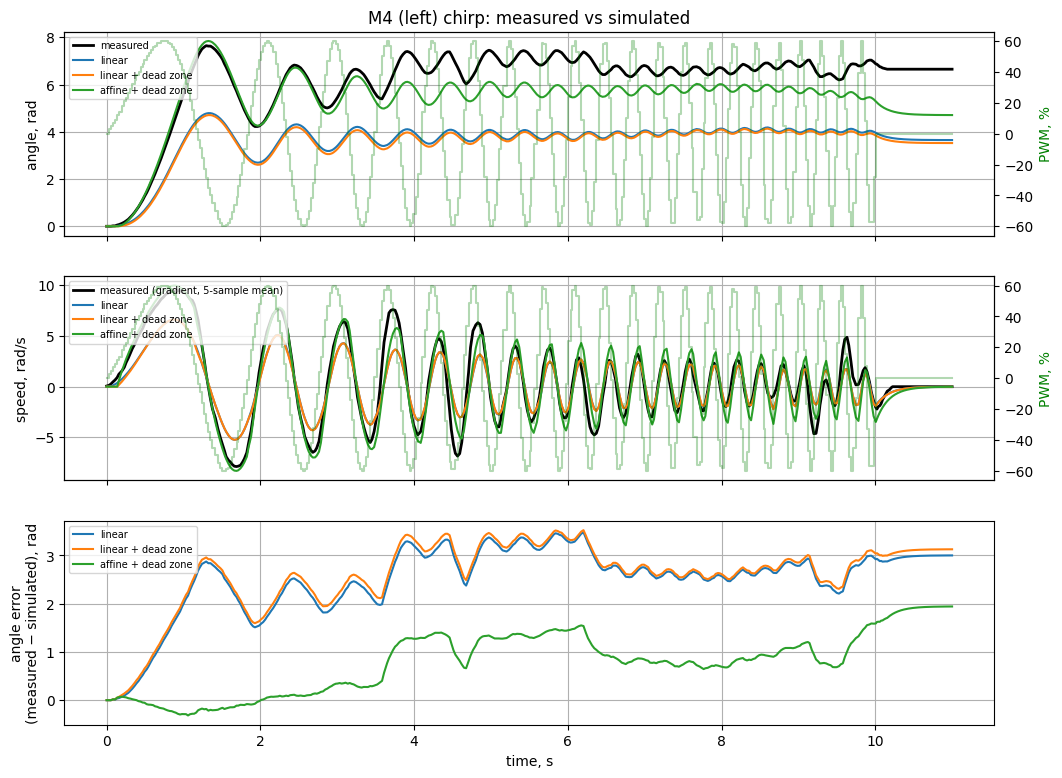

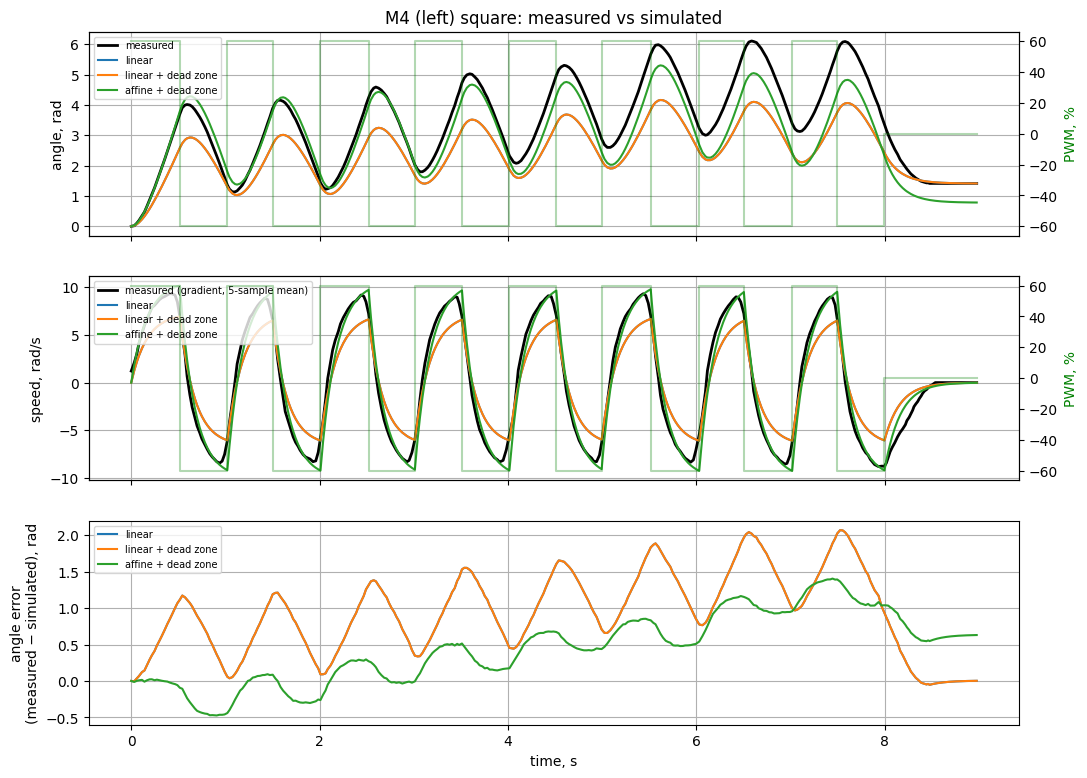

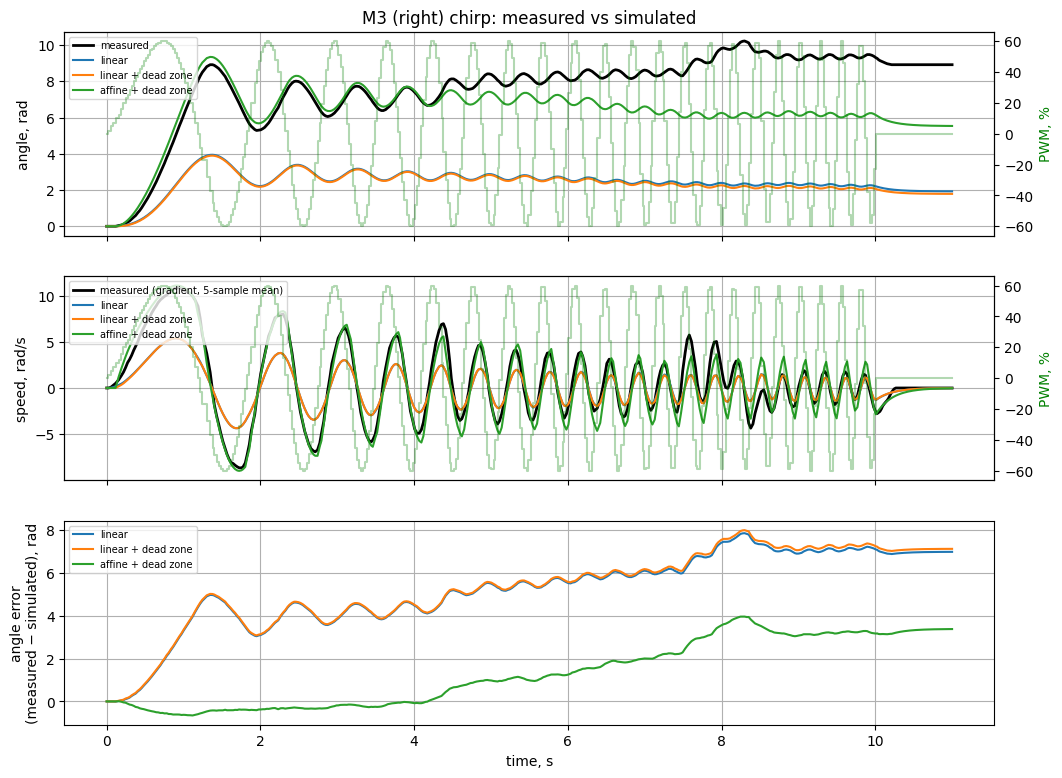

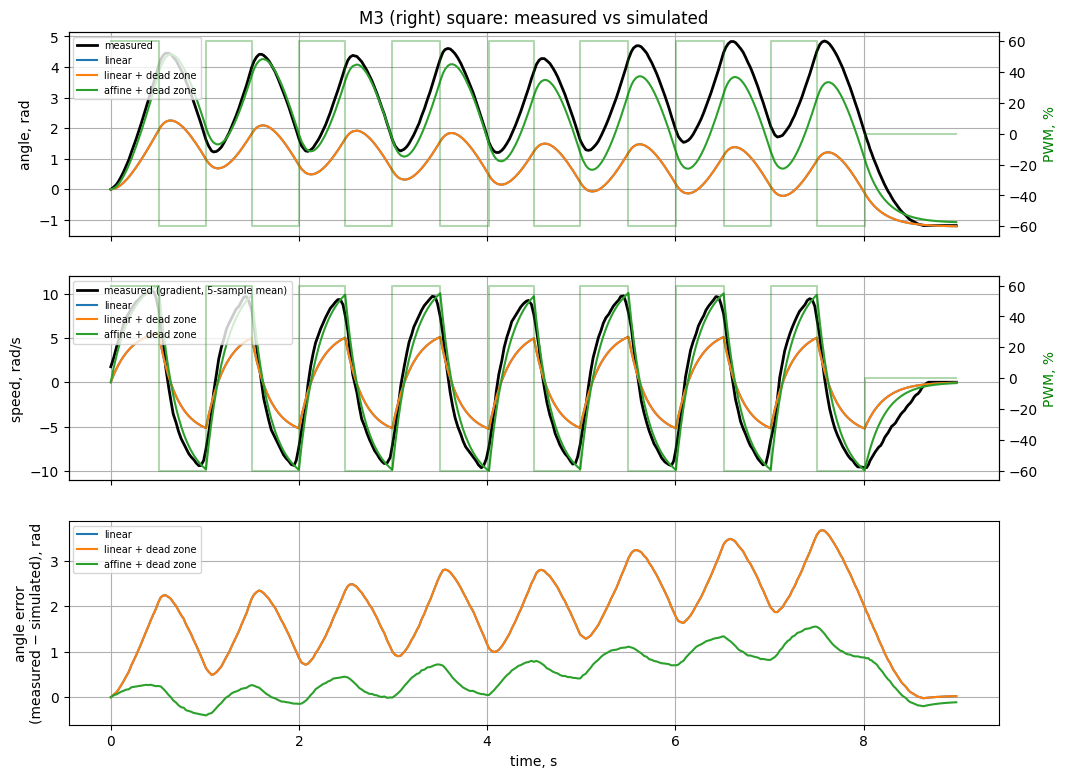

In [10]:
for (m, sig), (th, t, u, w, sims) in results.items():
    fig, ax = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
    ax[0].plot(t, th, 'k', lw=2, label='measured')
    ax[1].plot(t, w, 'k', lw=2, label=f'measured (gradient, {SMOOTH}-sample mean)')
    for k, (th_s, w_s) in sims.items():
        ax[0].plot(t, th_s, label=k); ax[1].plot(t, w_s, label=k)
        ax[2].plot(t, th - th_s, label=k)
    for a in ax[:2]:
        a2 = a.twinx(); a2.step(t, u, 'g', where='post', alpha=.3); a2.set_ylabel('PWM, %', color='g')
    ax[0].set(ylabel='angle, rad', title=f'{m} ({MOTORS[m]}) {sig}: measured vs simulated')
    ax[1].set(ylabel='speed, rad/s'); ax[2].set(ylabel='angle error\n(measured − simulated), rad', xlabel='time, s')
    for a in ax:
        a.grid(True); a.legend(fontsize=7, loc='upper left')
    plt.show()

*Caption:* complex signals on each motor: measured and simulated angle and speed with the input PWM
(green), and the angle error over time for the three model versions.

### Chirp: frequency response

For every input period of the chirp the speed amplitude is estimated from the angle swing,
`2πf · (max θ − min θ)/2`, and divided by the input amplitude in volts. The first-order model predicts
`1 / (k_e √(1 + (2π f T_m)²))`.

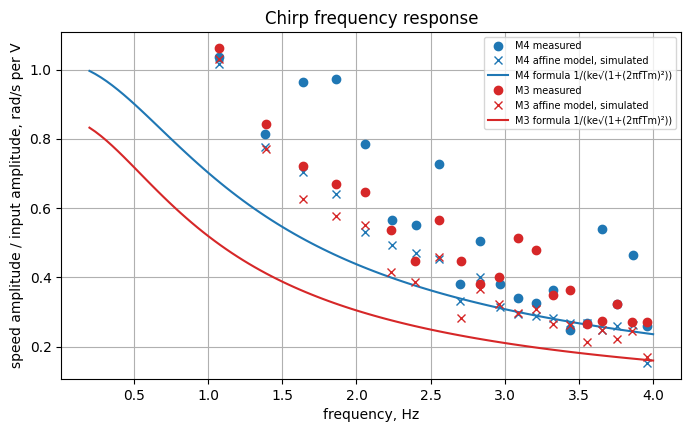

In [11]:
A, F0, F1, T = 60, 0.2, 4, 10      # chirp parameters of motor_signal.qrs: %, Hz, Hz, s
fig, ax = plt.subplots(figsize=(8, 4.5))
for m, c in zip(MOTORS, ['tab:blue', 'tab:red']):
    th, t, u, w, sims = results[m, 'chirp']
    up = np.flatnonzero((u[:-1] < 0) & (u[1:] >= 0)) + 1            # input starts a new period
    A_volt = A / 100 * params[m, 'forward']['Ub']
    for th_x, style, lab in [(th, 'o', 'measured'), (sims['affine + dead zone'][0], 'x', 'affine model, simulated')]:
        f, gain = [], []
        for a, b in zip(up[:-1], up[1:]):
            fi = F0 + (F1 - F0) * (t[a] + t[b]) / 2 / T          # chirp frequency in the middle of the period
            swing = th_x[a:b] - np.polyval(np.polyfit(t[a:b], th_x[a:b], 1), t[a:b])   # drift removed
            f.append(fi); gain.append(2 * np.pi * fi * np.ptp(swing) / 2 / A_volt)
        ax.plot(f, gain, style, color=c, label=f'{m} {lab}')
    p = params[m, 'forward']
    fr = np.linspace(0.2, 4, 100)
    ax.plot(fr, 1 / (p['ke'] * np.sqrt(1 + (2 * np.pi * fr * p['Tm']) ** 2)), '-', color=c,
            label=f'{m} formula 1/(ke√(1+(2πfTm)²))')
ax.set(xlabel='frequency, Hz', ylabel='speed amplitude / input amplitude, rad/s per V',
       title='Chirp frequency response'); ax.grid(True); ax.legend(fontsize=7); plt.show()

*Caption:* ratio of speed amplitude to input amplitude against frequency for the chirp, measured and
predicted.

## 8. Artifacts

### Zero drift

steps_M4_91.txt       : zero block 3.00 s, encoder change 0°, time() of the first sample 11 ms, change in the last 10 samples of each coast: max 0°
steps_M4_run2_91.txt  : zero block 2.98 s, encoder change 0°, time() of the first sample 19 ms, change in the last 10 samples of each coast: max 0°
steps_M3_91.txt       : zero block 2.99 s, encoder change 0°, time() of the first sample 19 ms, change in the last 10 samples of each coast: max 18°
steps_M3_run2_91.txt  : zero block 2.98 s, encoder change 0°, time() of the first sample 16 ms, change in the last 10 samples of each coast: max 16°


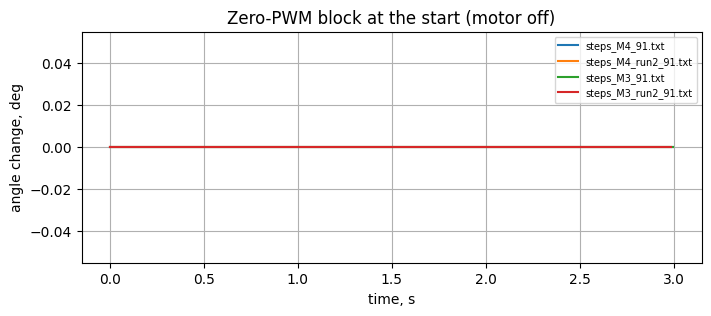

In [12]:
fig, ax = plt.subplots(figsize=(8, 3))
for m in MOTORS:
    for n in STEPS[m]:
        th, t, u, t0 = load(n)
        s, e = segments(u)[0]
        ax.plot(t[s:e], np.rad2deg(th[s:e] - th[s]), label=n)
        coast_end = [np.rad2deg(np.ptp(th[e2 - 10:e2])) for s2, e2 in segments(u)[1:] if u[s2] == 0]
        print(f'{n:22s}: zero block {t[e - 1]:.2f} s, encoder change {np.rad2deg(np.ptp(th[s:e])):.0f}°, '
              f'time() of the first sample {t0:.0f} ms, '
              f'change in the last 10 samples of each coast: max {max(coast_end):.0f}°')
ax.set(xlabel='time, s', ylabel='angle change, deg', title='Zero-PWM block at the start (motor off)')
ax.grid(True); ax.legend(fontsize=7); plt.show()

### Forward vs backward asymmetry and motor-to-motor spread

In [13]:
for m in MOTORS:
    f, b = params[m, 'forward'], params[m, 'backward']
    print(f'{m}: slope backward/forward {100 * (b["k"] / f["k"] - 1):+.1f} %, '
          f'offset {f["b"]:+.2f} / {b["b"]:+.2f} rad/s, mean Tm backward/forward {100 * (b["Tm"] / f["Tm"] - 1):+.1f} %')
for d in DIRS:
    a, b = params['M4', d], params['M3', d]
    print(f'{d:8s}: M3 vs M4 slope {100 * (b["k"] / a["k"] - 1):+.1f} %, ke {100 * (b["ke"] / a["ke"] - 1):+.1f} %, '
          f'Tm {100 * (b["Tm"] / a["Tm"] - 1):+.1f} %')
for lvl in (10, 50, 100):
    for m in MOTORS:
        r = fits[STEPS[m][0]]
        wf, wb = r[r[:, 0] == lvl, 1][0], r[r[:, 0] == -lvl, 1][0]
        print(f'  {m} at ±{lvl:3d} %: forward {wf:5.2f}, backward {wb:6.2f} rad/s ({100 * (abs(wb) / wf - 1):+.1f} %)')

M4: slope backward/forward -9.1 %, offset +3.39 / -3.40 rad/s, mean Tm backward/forward -5.7 %
M3: slope backward/forward -1.2 %, offset +5.86 / -5.48 rad/s, mean Tm backward/forward -7.1 %
forward : M3 vs M4 slope -15.4 %, ke +18.2 %, Tm +26.0 %
backward: M3 vs M4 slope -8.2 %, ke +8.9 %, Tm +24.0 %
  M4 at ± 10 %: forward  4.03, backward  -3.79 rad/s (-5.9 %)
  M3 at ± 10 %: forward  5.60, backward  -5.00 rad/s (-10.8 %)
  M4 at ± 50 %: forward  9.42, backward  -8.90 rad/s (-5.6 %)
  M3 at ± 50 %: forward 11.14, backward -10.74 rad/s (-3.6 %)
  M4 at ±100 %: forward 15.72, backward -14.56 rad/s (-7.4 %)
  M3 at ±100 %: forward 16.08, backward -15.52 rad/s (-3.5 %)


### Coasting after power-off

Angle turned in the 1 s after each step, against the model's free decay `ω_ss · T_m` (with the same T_m).

M4: measured coast / model at ±50 %: 1.3× forward, 1.4× backward
M3: measured coast / model at ±50 %: 1.7× forward, 1.6× backward


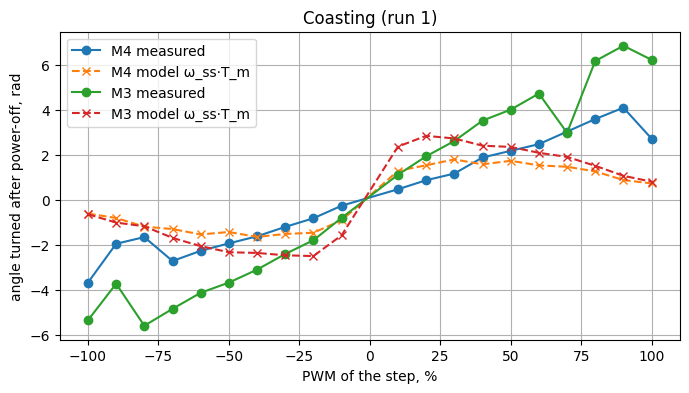

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
for m in MOTORS:
    th, t, u, _ = load(STEPS[m][0])
    segs = segments(u)
    pwm, coast = [], []
    for (s, e), (s2, e2) in zip(segs[:-1], segs[1:]):
        if u[s] != 0 and u[s2] == 0:
            pwm.append(u[s]); coast.append(th[e2 - 1] - th[s2])
    r = fits[STEPS[m][0]]
    ax.plot(pwm, coast, 'o-', label=f'{m} measured')
    ax.plot(r[:, 0], r[:, 1] * r[:, 2], 'x--', label=f'{m} model ω_ss·T_m')
    print(f'{m}: measured coast / model at ±50 %: '
          f'{coast[pwm.index(50)] / (r[r[:, 0] == 50, 1] * r[r[:, 0] == 50, 2])[0]:.1f}× forward, '
          f'{coast[pwm.index(-50)] / (r[r[:, 0] == -50, 1] * r[r[:, 0] == -50, 2])[0]:.1f}× backward')
ax.set(xlabel='PWM of the step, %', ylabel='angle turned after power-off, rad', title='Coasting (run 1)')
ax.grid(True); ax.legend(); plt.show()

### Gear backlash and lag at reversals (square wave)

Time from each input reversal to the first sample where the wheel has turned 2° in the new direction,
measured and in the affine model (the model has no backlash and no dead time).

In [15]:
def reversal_lag(th, t, u, move=np.deg2rad(2)):
    lags = []
    for i in np.flatnonzero(u[1:] * u[:-1] < 0) + 1:     # PWM changed sign
        x = np.sign(u[i]) * th[i:]                  # angle measured in the new direction
        j = i + np.argmax(x - np.minimum.accumulate(x) >= move)   # 2° past the turning point
        lags.append((t[j] - t[i]) * 1000)
    return np.array(lags)


for m in MOTORS:
    th, t, u, w, sims = results[m, 'square']
    meas = reversal_lag(th, t, u)
    model_lag = reversal_lag(sims['affine + dead zone'][0], t, u)
    print(f'{m}: reversal → 2° in the new direction: measured {meas.mean():.0f} ± {meas.std():.0f} ms, '
          f'model {model_lag.mean():.0f} ms, measured − model {meas.mean() - model_lag.mean():+.0f} ms')

M4: reversal → 2° in the new direction: measured 122 ± 13 ms, model 158 ms, measured − model -36 ms
M3: reversal → 2° in the new direction: measured 134 ± 13 ms, model 175 ms, measured − model -42 ms


### Battery sag

Voltages from `battery.txt` and the speed at the same level in run 1 and run 2.

In [16]:
for m in MOTORS:
    n1, n2 = STEPS[m]
    r1, r2 = fits[n1], fits[n2]
    dw = 100 * (np.abs(r2[:, 1]) / np.abs(r1[:, 1]) - 1)
    print(f'{m}: U_bat run 1 {U_bat[n1]:.3f} V, run 2 {U_bat[n2]:.3f} V ({100 * (U_bat[n2] / U_bat[n1] - 1):+.2f} %); '
          f'speed run 2 vs run 1: mean {dw.mean():+.2f} %, max |Δ| {np.abs(dw).max():.2f} %')
print(f'Whole session: {min(U_bat.values()):.3f} … {max(U_bat.values()):.3f} V')

M4: U_bat run 1 11.843 V, run 2 11.895 V (+0.44 %); speed run 2 vs run 1: mean +0.59 %, max |Δ| 4.74 %
M3: U_bat run 1 11.889 V, run 2 11.849 V (-0.33 %); speed run 2 vs run 1: mean -0.34 %, max |Δ| 3.19 %
Whole session: 11.843 … 11.895 V


### Encoder quantisation and differentiation noise

The encoder counts whole degrees. Over one ≈ 20 ms sample one count is 0.87 rad/s, so the raw
`np.gradient` speed is noisy; the table compares the noise in the steady part (last 1 s) of a few steps.

M4  20 %: speed std raw 0.46 rad/s, smoothed (5 samples) 0.16 rad/s
M4  50 %: speed std raw 0.46 rad/s, smoothed (5 samples) 0.16 rad/s
M4  90 %: speed std raw 0.92 rad/s, smoothed (5 samples) 0.31 rad/s


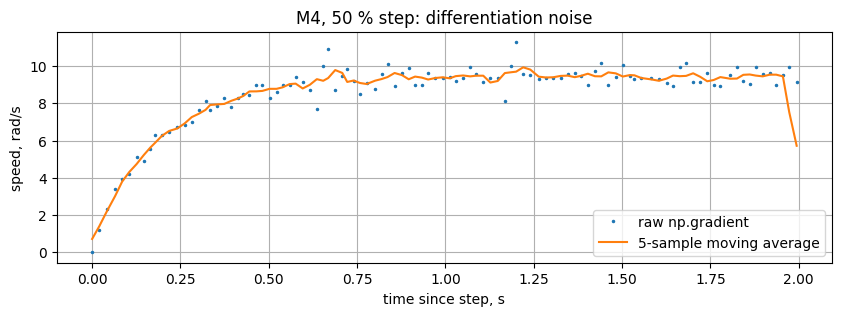

In [17]:
th, t, u, _ = load(STEPS['M4'][0])
fig, ax = plt.subplots(figsize=(10, 3))
for lvl in (20, 50, 90):
    s, e = next(se for se in segments(u) if u[se[0]] == lvl)
    w_raw = np.gradient(th[s:e], t[s:e])
    keep = t[s:e] - t[s] > 1.0
    w_sm = smooth(w_raw)[keep][SMOOTH:-SMOOTH]
    print(f'M4 {lvl:3d} %: speed std raw {w_raw[keep].std():.2f} rad/s, smoothed ({SMOOTH} samples) {w_sm.std():.2f} rad/s')
    if lvl == 50:
        ax.plot(t[s:e] - t[s], w_raw, '.', ms=3, label='raw np.gradient')
        ax.plot(t[s:e] - t[s], smooth(w_raw), label=f'{SMOOTH}-sample moving average')
ax.set(xlabel='time since step, s', ylabel='speed, rad/s', title='M4, 50 % step: differentiation noise')
ax.grid(True); ax.legend(); plt.show()

## 9. Analysis

✍️ *Write each paragraph in your own words, using the numbers above.*

**1. How well does the first-order model with constant T_m and k_e describe the motor?** Give the fit
percentage on the complex signal and point to where the error is largest.

…

**2. Forward vs backward rotation:** are the two directions the same motor? Should a controller use one set
of parameters or two?

…

**3. Artifacts:** which did you find, how large are they, and which of them matter for odometry next week?

…

**4. Complex signal:** which did you choose and what did it show that the step series did not?

…